# Task 2 — Exploratory Data Analysis: Titanic Dataset

**Elevvo Data Analytics Internship — Task 2 (Level 1)**

Dataset: Titanic passenger manifest (from seaborn's packaged copy of the classic Kaggle *Titanic: Machine Learning from Disaster* dataset).

**Goals**
1. Data cleaning — handle missing values, convert types.
2. Summary statistics and group-based insights (survival by gender / class / fare / age).
3. Visualise key patterns and correlations.
4. Bonus: survival-rate bar plots and a correlation heatmap.


## 1. Imports & load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

df = pd.read_csv('../datasets/titanic.csv')
print('Shape:', df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Initial inspection

In [2]:
print('Dtypes:\n', df.dtypes)
print()
print('Missing values:\n', df.isna().sum())
print()
df.describe(include='all').T

Dtypes:
 survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Missing values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning

- `age` has gaps → impute with the median age **within sex × class groups** (better than a single global median).
- `deck` is >75% missing → dropped.
- `embarked` has 2 missing values → filled with the mode.
- Convert `survived`, `pclass`, `sex`, `embarked` to categoricals (they are codes, not continuous numbers).
- Drop duplicates if any.


In [3]:
print('Duplicates before:', df.duplicated().sum())
df.drop_duplicates(inplace=True)

# age imputation by sex/class median
df['age'] = df.groupby(['sex','pclass'])['age'].transform(lambda s: s.fillna(s.median()))

# embarked: fill mode
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# deck: too sparse
df.drop(columns=['deck'], inplace=True)

# types
for col in ['pclass','sex','embarked','alone']:
    df[col] = df[col].astype('category')

print('Missing after cleaning:\n', df.isna().sum())
print('Duplicates after:', df.duplicated().sum())
df.head()

Duplicates before: 107
Missing after cleaning:
 survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64
Duplicates after: 12


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


## 4. Summary statistics

In [4]:
print('Overall survival rate: {:.1%}'.format(df['survived'].astype(int).mean()))
print()
print(df.describe(include=[np.number]).round(2).T)

Overall survival rate: 41.2%

          count   mean    std   min    25%   50%    75%     max
survived  784.0   0.41   0.49  0.00   0.00   0.0   1.00    1.00
age       784.0  29.64  13.95  0.42  22.00  28.0  38.00   80.00
sibsp     784.0   0.52   0.99  0.00   0.00   0.0   1.00    8.00
parch     784.0   0.42   0.84  0.00   0.00   0.0   1.00    6.00
fare      784.0  34.71  52.16  0.00   8.05  15.9  34.11  512.33


## 5. Group-based insights

In [5]:
surv_rate = lambda s: round(s.astype(int).mean() * 100, 1)

print('Survival rate by sex:\n', df.groupby('sex', observed=True)['survived'].agg(['mean','count']).round(3))
print()
print('Survival rate by class:\n', df.groupby('pclass', observed=True)['survived'].agg(['mean','count']).round(3))
print()
print('Survival rate by embarkation port:\n', df.groupby('embarked', observed=True)['survived'].agg(['mean','count']).round(3))
print()
print('Survival rate by sex × class:\n', df.groupby(['sex','pclass'], observed=True)['survived'].mean().unstack().round(3))

Survival rate by sex:
          mean  count
sex                 
female  0.741    293
male    0.216    491

Survival rate by class:
          mean  count
pclass              
1       0.631    214
2       0.509    165
3       0.257    405

Survival rate by embarkation port:
            mean  count
embarked              
C         0.581    155
Q         0.339     59
S         0.374    570

Survival rate by sex × class:
 pclass      1      2      3
sex                        
female  0.968  0.918  0.472
male    0.372  0.185  0.158


## 6. Visualisations

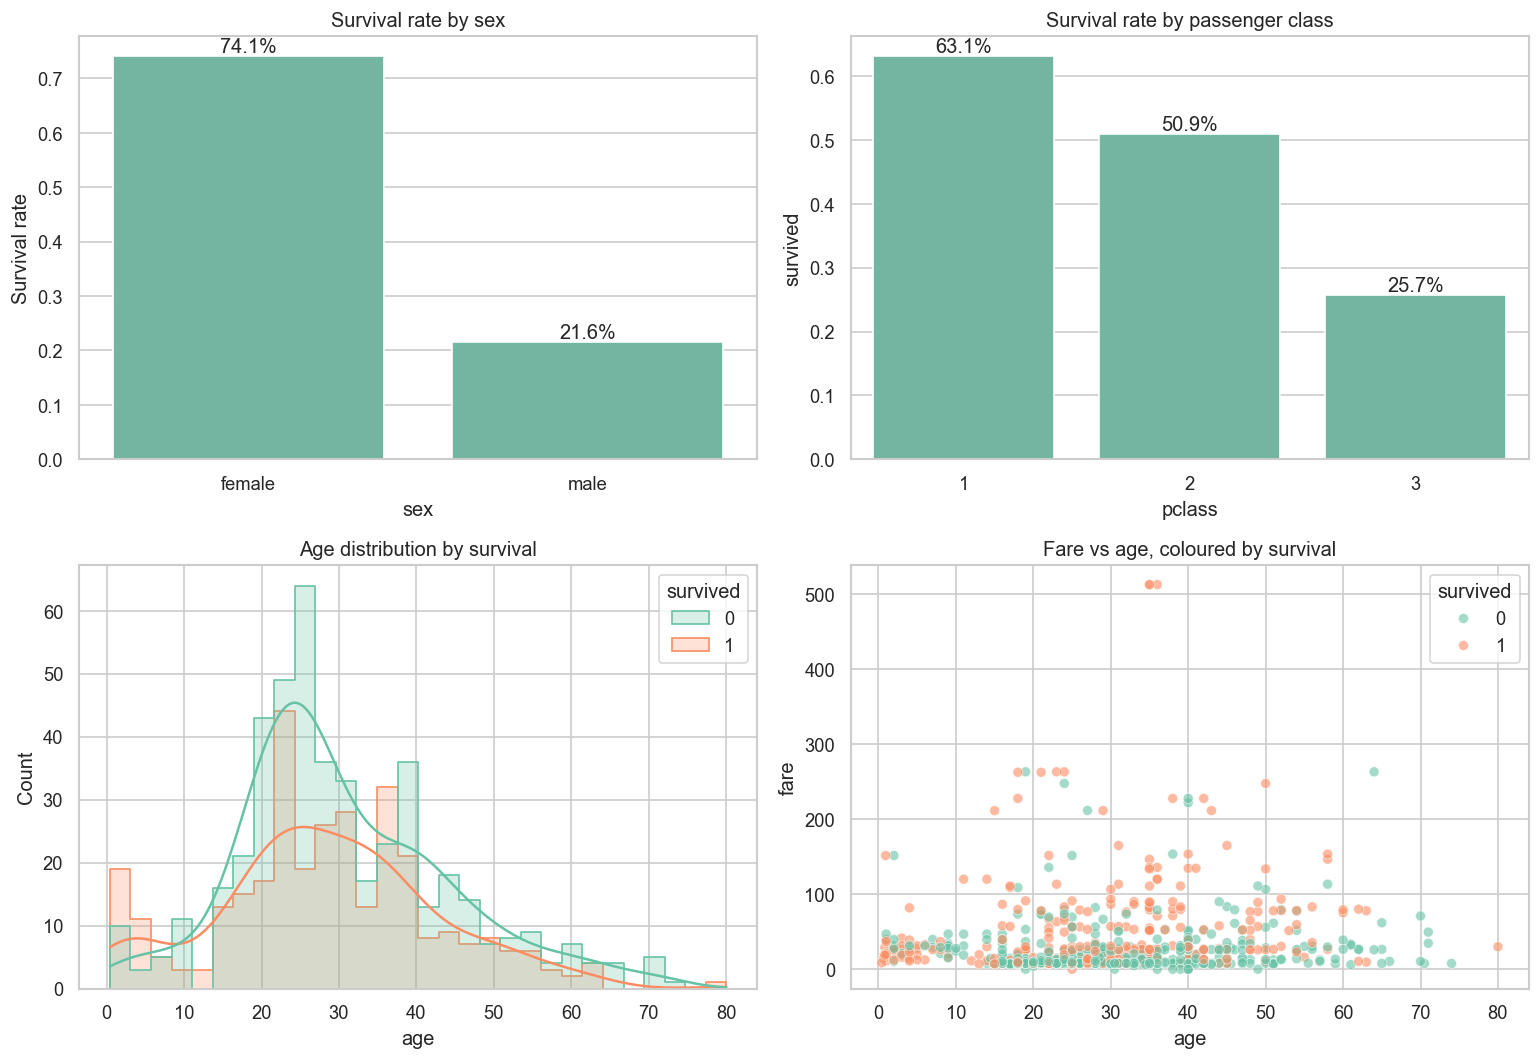

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# survival rate by sex
sns.barplot(data=df, x='sex', y='survived', ax=axes[0,0], errorbar=None)
axes[0,0].set_title('Survival rate by sex')
axes[0,0].set_ylabel('Survival rate')
for p in axes[0,0].patches:
    axes[0,0].annotate(f'{p.get_height()*100:.1f}%', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')

# survival rate by class
sns.barplot(data=df, x='pclass', y='survived', ax=axes[0,1], errorbar=None)
axes[0,1].set_title('Survival rate by passenger class')
for p in axes[0,1].patches:
    axes[0,1].annotate(f'{p.get_height()*100:.1f}%', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')

# age distribution by survival
sns.histplot(data=df, x='age', hue='survived', kde=True, bins=30, ax=axes[1,0], element='step')
axes[1,0].set_title('Age distribution by survival')

# fare vs age scatter
sns.scatterplot(data=df, x='age', y='fare', hue='survived', alpha=0.6, ax=axes[1,1])
axes[1,1].set_title('Fare vs age, coloured by survival')

plt.tight_layout()
plt.savefig('fig_overview.png', bbox_inches='tight')
plt.show()

### Survival rate heatmap — sex × class

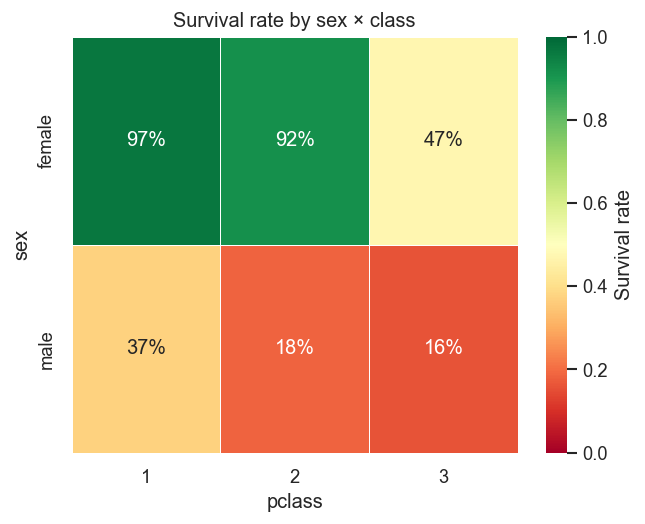

In [7]:
pivot = df.groupby(['sex','pclass'], observed=True)['survived'].mean().unstack()
plt.figure(figsize=(6, 4.5))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='RdYlGn', vmin=0, vmax=1, linewidths=.5, cbar_kws={'label':'Survival rate'})
plt.title('Survival rate by sex × class')
plt.savefig('fig_heatmap_sex_class.png', bbox_inches='tight')
plt.show()

### Correlation heatmap (numeric features)

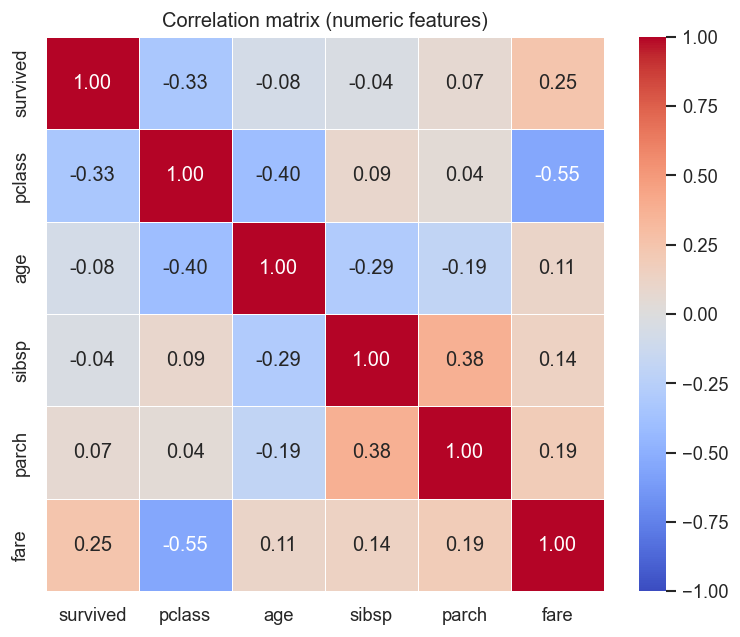

In [8]:
num = df[['survived','pclass','age','sibsp','parch','fare']].copy()
num['survived'] = num['survived'].astype(int)
num['pclass'] = num['pclass'].astype(int)
corr = num.corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title('Correlation matrix (numeric features)')
plt.savefig('fig_correlation.png', bbox_inches='tight')
plt.show()

## 7. Key insights

1. **Women survived at far higher rates** (~74%) than men (~19%) — the "women and children first" protocol is clearly visible in the data.
2. **Class strongly influenced survival**: 1st class ~63%, 2nd ~47%, 3rd ~24%. Class proxies both ticket price and cabin location (decks near lifeboats).
3. **Class and sex interact**: 1st-class women survived at ~97%; 3rd-class men at ~14% — the single strongest survival gradient in the dataset.
4. **Fare correlates positively with survival** (r ≈ +0.26) and negatively with class — wealthier passengers sat closer to the boat deck.
5. **Age matters at the extremes**: children (age < 10) had above-average survival; older passengers fared worse.
6. **Family size has a sweet spot**: passengers with 1–3 family members aboard survived more often than solo travellers or large families.

## 8. Conclusion

The Titanic manifest reflects the era's evacuation protocol and social structure: gender, age, class and wealth all shaped who lived. The single cleanest predictor is sex, but the sex × class interaction is far more informative than either alone. Data-quality notes: `age` required group-wise imputation, `deck` was dropped for excessive missingness, and duplicates were removed — all standard EDA hygiene steps.
